# Part A — Bilateral Filtering preprocessing pipeline

An edge-preserving smoothing preprocessing pipeline for cervical colposcopy
images. This notebook is a REWRITE of the previous QI-SABP preprocessing
notebook: **all QI-SABP preprocessing techniques and configuration have been
removed**, and the preprocessing is now a single **Bilateral Filtering**
stage followed by the same style of table-only validation.

## What was removed (previous QI-SABP machinery)

* Quantum-inspired fused saliency (Sobel + FFT spectral residual +
  multi-scale contrast + local entropy) and all of its fusion weights.
* Glare mask, FOV-rim saliency masking, hard-mask hole filling, rim/size
  component rules, minimum-area filter, whiteness channel.
* Soft saliency mask `W ∈ [0,1]` and edge-aware continuous bit allocation
  (8/4-bit salient vs non-salient, edge boost, luma floor).
* Adaptive dithered quantization, YCbCr 4:2:0 chroma subsampling,
  soft-blend with the original.
* NLM pre-denoise and partial histogram matching.
* The bilateral *post*-filter that used to act only on the soft-mask
  boundary — it is now promoted to **the** preprocessing stage, applied to
  the full frame.
* The analytic bits/px bookkeeping, the frozen `cache_hash` assert, the
  QI-SABP mask-variant ablation rows, and the unsharp-mask sharpen (Step 1):
  the bilateral filter now takes the raw resized image directly.

## What is "bilateral filtering" here

`cv2.bilateralFilter` replaces each pixel with a weighted average of its
neighbourhood in which the weight of a neighbour is the product of

* a **spatial Gaussian** — neighbours far away count less
  (controlled by the diameter `d` and `sigma_space`), and
* a **range (intensity) Gaussian** — neighbours whose intensity differs a
  lot from the centre pixel count less (controlled by `sigma_color`).

Low-contrast texture and noise are therefore averaged away, while
high-contrast boundaries (tissue edges, vessel walls) keep their weights
suppressed and survive. This is the property that makes bilateral filtering
a standard edge-preserving denoiser. Everything in this notebook is
standard classical image processing; nothing is quantum-inspired and there
are no saliency masks or bit budgets anywhere in the pipeline.

## Pipeline overview

* Step 1 — Load image, convert BGR→RGB, resize to 200×200. No sharpening.
* Step 2 — Bilateral filter on the full RGB frame
  (`d=5, sigma_color=25, sigma_space=3` — the settings the previous
  notebook used for its optional bilateral post-filter).

## Output

The pipeline returns a **lossy image** (uint8 RGB, same shape as the
input): bilateral filtering is a smoothing (lossy) operation. It is NOT a
compression scheme. The pipeline is therefore evaluated as an
image-processing technique (distortion, colour stability, diagnostic
structure), not as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires a
  multi-patient / multi-technique notebook).
* It does NOT demonstrate a clinical benefit on this single patient.

## Validation (Part B)

Part B computes **11 metrics** per image, inside the field-of-view (FOV)
mask only, against the ORIGINAL (resize-only) image:

| #   | Metric            | Group      | Better |
|-----|-------------------|------------|--------|
| m1  | PSNR (dB)         | fidelity   | up     |
| m2  | SSIM              | fidelity   | up     |
| m3  | ΔE76              | colour     | down   |
| m4  | a* correlation    | colour     | up     |
| m5  | \|a*\| shift      | colour     | down   |
| m6  | Vessel Dice       | structure  | up     |
| m7  | Edge IoU          | structure  | up     |
| m8  | Sharpness ratio   | quality    | neutral|
| m9  | Noise ratio       | quality    | down   |
| m10 | Saturation ratio  | quality    | neutral|
| m11 | Luma bits         | cost       | down   |


In [1]:
# ============================================================
# Cell 1.1 -- Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
import hashlib as _hashlib
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
try:
    from skimage.filters import frangi as _frangi_fn
    _SKIMAGE_FRANGI_OK = True
except ImportError:
    _SKIMAGE_FRANGI_OK = False
    print("[warn] skimage.filters.frangi not available -- "
          "the vessel map falls back to Sobel ridge detection.")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for CSV artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nBilateral Filtering Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Bilateral Filtering Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 1.2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Bilateral Filtering (Step 2, the ONLY preprocessing stage) ----
# These are the settings the previous notebook used for its optional
# bilateral POST-filter; they are now the parameters of the single
# preprocessing stage. d is the pixel-neighbourhood diameter;
# sigma_color controls how much intensity difference gets averaged away
# (larger = more smoothing); sigma_space controls how far away neighbours
# still influence each other (larger = smoother, less edge-preserving).
BF_D            = 5
BF_SIGMA_COLOR  = 25
BF_SIGMA_SPACE  = 3

# ---- Bootstrap (Part B) ----
BOOTSTRAP_N_BOOT = 2000
BOOTSTRAP_SEED   = 42

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation subset ----
SUBSET_PER_CLASS = None   # None = use every image found

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  bilateral filter: d={BF_D}, sigma_color={BF_SIGMA_COLOR}, "
      f"sigma_space={BF_SIGMA_SPACE}")
print("  (single preprocessing stage -- no sharpen, no saliency, no quantization)")
print(f"  bootstrap: {BOOTSTRAP_N_BOOT} resamples, seed={BOOTSTRAP_SEED}")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  bilateral filter: d=5, sigma_color=25, sigma_space=3
  (single preprocessing stage -- no sharpen, no saliency, no quantization)
  bootstrap: 2000 resamples, seed=42


In [3]:
# ============================================================
# Cell 1.3 -- Preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
#            NOTE: no sharpening -- the bilateral filter (cell 1.4)
#            is the ONLY preprocessing stage.
# ============================================================
def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. Single source of truth (no sharpening)."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize.
    Case-insensitive dedupe by filename so the same physical file is never
    loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (no sharpening -- bilateral filter is the only preprocessing)")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X, y, paths, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X)} | masks matched: {n_with_mask}/{len(X)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X = np.stack(X_synth).astype(np.uint8)
    y = np.array(y_synth)
    paths = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y, range(len(y)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X[i] = np.clip(X[i].astype(np.int32) + np.array([dr, dg, db]),
                       0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X)} images, "
          f"{int(masks_raw.any((1, 2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (no sharpening -- bilateral filter is the only preprocessing)
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


In [4]:
# ============================================================
# Cell 1.4 -- Bilateral Filtering core + technique wrapper
# ============================================================
def bilateral_filter_preprocess(img_rgb, d=None, sigma_color=None, sigma_space=None):
    """Bilateral filter on the full RGB frame. The ONLY preprocessing stage.

    cv2.bilateralFilter weights each neighbour by a spatial Gaussian
    (sigma_space, diameter d) times a range Gaussian (sigma_color), so flat
    areas are smoothed while high-contrast edges are preserved. On a
    3-channel image OpenCV computes the joint range weight across channels.
    Returns uint8 RGB, same shape as the input.
    """
    d           = BF_D           if d is None           else d
    sigma_color = BF_SIGMA_COLOR if sigma_color is None else sigma_color
    sigma_space = BF_SIGMA_SPACE if sigma_space is None else sigma_space
    if d % 2 == 0:
        d += 1                            # cv2.bilateralFilter accepts any d >= 1
    return cv2.bilateralFilter(img_rgb, d=d,
                               sigmaColor=sigma_color,
                               sigmaSpace=sigma_space)


# ---- Technique wrapper for the Part B validator -------------------------
BF_DEFAULTS = {}

def bilateral_technique(img, params=None, seed=0):
    """Bilateral Filtering preprocessing, exposed to the Part B validator.

    Signature: bilateral_technique(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    `params` is accepted for API compatibility but ignored (fixed module-level
    configuration; no tuning on a single patient). `seed` is accepted for API
    symmetry only: cv2.bilateralFilter is fully deterministic, so the seed
    does not change the output.
    """
    return bilateral_filter_preprocess(img)


# Quick smoke test on the first image
_sm = bilateral_technique(X[0], BF_DEFAULTS, seed=12345)
assert _sm.shape == X[0].shape and _sm.dtype == np.uint8, \
    f"bilateral_technique smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(bilateral_technique(X[0], BF_DEFAULTS, seed=12345), _sm), \
    "bilateral_technique is not deterministic for the same seed"
print(f"bilateral_technique() ready  |  BF_DEFAULTS = {BF_DEFAULTS}  |  "
      f"smoke test on X[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int) - X[0].astype(int)).mean():.3f}")


bilateral_technique() ready  |  BF_DEFAULTS = {}  |  smoke test on X[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=2.048


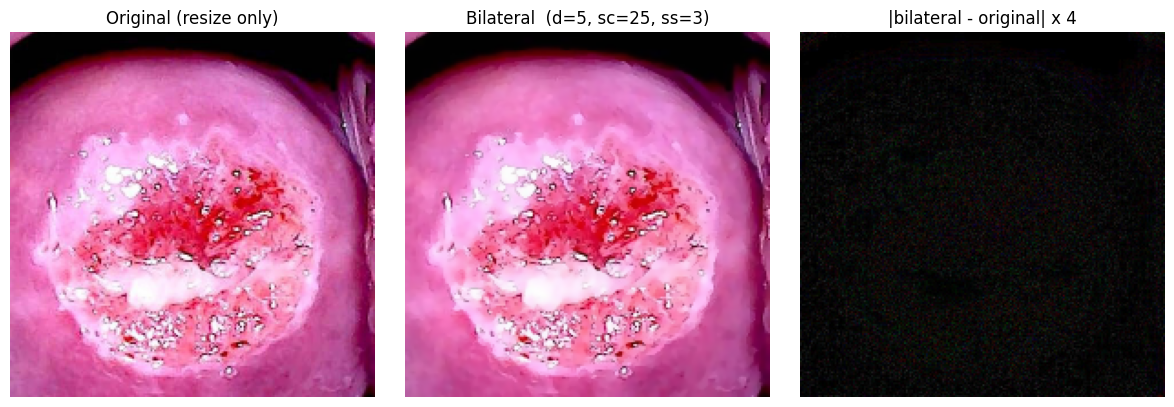

In [5]:
# ============================================================
# Cell 1.5 -- Bilateral filter before/after visualisation
# ============================================================
def show_bilateral_effect(img_rgb):
    """Show original / bilateral-filtered / absolute difference for one image."""
    filtered = bilateral_filter_preprocess(img_rgb)
    diff = np.abs(filtered.astype(np.int16) - img_rgb.astype(np.int16)).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(img_rgb)
    ax[0].set_title("Original (resize only)")
    ax[0].axis("off")
    ax[1].imshow(filtered)
    ax[1].set_title(f"Bilateral  (d={BF_D}, sc={BF_SIGMA_COLOR}, ss={BF_SIGMA_SPACE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")   # x4 to make the change visible
    ax[2].set_title("|bilateral - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


show_bilateral_effect(X[0])


# Part B — Validation: 11 metrics

Single-patient frames, grouped into distinct dHash clusters. The frames are
NOT independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Bilateral Filtering (`d=5, sigma_color=25, sigma_space=3`),
applied to the full RGB frame. No region allocation, no masks, no
quantization, no sharpening.

**Metrics:** 11 metrics in 4 groups (fidelity, colour, diagnostic structure,
quality + cost). All computed inside the FOV mask only, per image, against
the ORIGINAL (resize-only) image: PSNR (dB), SSIM, ΔE76, a* correlation,
|a*| shift, Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio, Saturation
ratio, Luma bits.

**Luma bits (m11):** bilateral filtering never re-quantises, so the nominal
depth stays 8 bits. m11 reports the **effective** luma bit depth instead:
`log2(number of distinct grey levels inside the FOV)` of the PROCESSED
image. Sensor noise spends many grey levels; smoothing collapses
near-duplicate levels, so the effective value drifts below 8.0 as smoothing
increases. On real 8-bit images the Identity row sits close to 8.0 (an
8-bit frame uses most levels); smooth synthetic frames use fewer levels.

**Tables only.** No figures, no plots. T1 (main), T5 (per cluster),
T6 (caveats).


In [6]:
# ============================================================
# Cell 4.1 -- Freeze inputs: data fingerprint, FOV masks, cluster ids.
# ============================================================

def _dhash(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()


def compute_fov(img_rgb, thr=15):
    """FOV mask: largest bright connected region, holes filled, notches
    filled by a convex hull clipped to the region's bounding box (same as
    the previous notebook's validator FOV)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (fills black triangles / zigzag teeth at the frame edges)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1 + 1, x0:x1 + 1] = True
        hull_mask = hull_mask & bbox
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov


# ---- Inputs -------------------------------------------------------------
# NOTE: there is no sharpening in this pipeline, so the loaded stack IS the
# original (resize-only) image and the FOV source at the same time. The
# previous notebook's separate X_base (sharpened) / X_raw (resize-only)
# split existed only because its Part A sharpened; that split is gone.
images = X                     # (N, 200, 200, 3) uint8 RGB, resize-only
masks  = masks_raw             # clinician lesion masks (synthetic in fallback)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([compute_fov(images[i]) for i in range(n_images)])

# dHash clustering (same as the previous validator)
hs = [_dhash(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                         for uc in np.unique(cluster_ids)], dtype=int)

# ---- Data fingerprint (provenance only -- NO frozen-hash assert) --------
# The previous notebook asserted cache_hash == "12f68b681210" because its
# Part A was frozen. This notebook has no frozen part, so the hash is
# printed for provenance only and never asserted.
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
data_fingerprint = _h.hexdigest()[:12]
print(f"data_fingerprint = {data_fingerprint}  (provenance only, not asserted)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  masks matched: {int(masks.any((1, 2)).sum())}/{len(masks)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


data_fingerprint = 4c30f945635c  (provenance only, not asserted)
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  masks matched: 0/128
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [7]:
# ============================================================
# Cell 4.2 -- validator + helper functions. Computes 11 metrics
#             inside the FOV only.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    if _SKIMAGE_FRANGI_OK:
        try:
            v = _frangi_fn(gray, black_ridges=False)
            v = v / (v.max() + 1e-8)
            return v.astype(np.float32)
        except Exception:
            pass
    # Fallback: Sobel-based ridge detection
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    v = np.hypot(gx, gy)
    v = v / (v.max() + 1e-8)
    return v.astype(np.float32)


def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A&B|/(|A|+|B|).
    This has more resolution than a pixel-wise correlation (which sits at
    0.997-0.999 for every variant)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom


def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)


def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])


def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)


def _specular_mask(img_rgb):
    """Specular/glare mask (same as the previous validator)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)


def _effective_luma_bits(img_rgb, fov_mask):
    """m11 -- effective luma bit depth inside the FOV.

    log2 of the number of DISTINCT grey levels the image actually uses
    inside the FOV. uint8 stores 8 nominal bits and bilateral filtering
    never re-quantises, but smoothing collapses near-duplicate levels, so
    the effective value drifts below 8.0 as smoothing increases.
    """
    f = np.asarray(fov_mask, dtype=bool)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    n_levels = int(np.unique(gray[f]).size)
    return float(np.log2(max(n_levels, 1)))


def bilateral_validator(original, processed, fov_mask):
    """Compute the 10 pixel metrics inside the FOV only, per image.

    Returns a dict with keys m1..m10:
      m1  PSNR (dB)                  up
      m2  SSIM                       up
      m3  DeltaE76 (CIE76 dE)        down
      m4  a* correlation             up
      m5  |a*| shift                 down
      m6  Vessel Dice                up
      m7  Edge IoU                   up
      m8  Sharpness ratio (out/in)   neutral (0.9-1.1)
      m9  Noise ratio (out/in)       down
      m10 Saturation ratio (out/in)  neutral (at most 1)

    m11 (Luma bits, effective) is computed separately by
    _effective_luma_bits so the Identity row is measured the same way.
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: DeltaE76 (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |a*| shift
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of the high-pass residual
    #     in the smoothest 30% of the FOV
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures NEW
    #      saturated pixels introduced by the technique, NOT glare removal.
    #      A ratio > 1 means the technique adds saturated pixels.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)


# Metric metadata (name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",     "fidelity",  "up"),
    ("m2",  "SSIM",          "fidelity",  "up"),
    ("m3",  "ΔE76",          "colour",    "down"),
    ("m4",  "a* correlation","colour",    "up"),
    ("m5",  "|a*| shift",    "colour",    "down"),
    ("m6",  "Vessel Dice",   "structure", "up"),
    ("m7",  "Edge IoU",      "structure", "up"),
    ("m8",  "Sharpness ratio","quality",  "neutral"),
    ("m9",  "Noise ratio",   "quality",   "down"),
    ("m10", "Saturation ratio","quality", "neutral"),
    ("m11", "Luma bits",     "cost",      "down"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("bilateral_validator ready: 11 metrics (m1..m11).")


bilateral_validator ready: 11 metrics (m1..m11).


In [8]:
# ============================================================
# Cell 4.3 -- Compute the 11 metrics per image. Write per-image CSV.
#             Technique: Bilateral Filtering. Reference: Identity.
# ============================================================
PER_IMAGE_CSV = os.path.join(SAVE_DIR, "per_image_metrics.csv")
if os.path.exists(PER_IMAGE_CSV):
    os.remove(PER_IMAGE_CSV)
    print(f"  Deleted stale {PER_IMAGE_CSV}")

TECHNIQUE = "Bilateral Filtering"
processed_cache = {}   # image_idx -> uint8 RGB (bilateral output)

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = bilateral_technique(orig, BF_DEFAULTS, seed=SEED + i)
    m = bilateral_validator(orig, proc, fov_i)
    m["m11"] = _effective_luma_bits(proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[i] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

# ---- Identity reference row (ideal values, not ranked) ------------------
rows_id = []
for i in range(n_images):
    m = bilateral_validator(images[i], images[i], fov[i])
    m["m11"] = _effective_luma_bits(images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)

df_all = pd.DataFrame(rows + rows_id)
df_all.to_csv(PER_IMAGE_CSV, index=False, encoding="utf-8-sig")
print(f"Wrote {PER_IMAGE_CSV} ({len(df_all)} rows: "
      f"{len(rows)} {TECHNIQUE} + {len(rows_id)} Identity)")
print(f"  mean luma bits (effective, {TECHNIQUE}) = "
      f"{df_all.loc[df_all['technique'] == TECHNIQUE, 'm11'].mean():.3f}")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results\per_image_metrics.csv (256 rows: 128 Bilateral Filtering + 128 Identity)
  mean luma bits (effective, Bilateral Filtering) = 7.935


In [9]:
# ============================================================
# Cell 4.4 -- Load the per-image CSV back and run sanity checks.
#             Fixed technique list (no stale technique can leak in).
# ============================================================
techniques = [TECHNIQUE, "Identity"]

merged = pd.read_csv(PER_IMAGE_CSV, encoding="utf-8-sig")

for _t in techniques:
    _n = int((merged["technique"] == _t).sum())
    assert _n == n_images, f"technique {_t!r} has {_n} rows, expected {n_images}"

_cluster_sets = {t: set(merged.loc[merged["technique"] == t, "cluster_id"])
                 for t in techniques}
assert _cluster_sets[TECHNIQUE] == _cluster_sets["Identity"], \
    "cluster id sets differ between techniques"

metric_cols = [mk for mk in METRIC_KEYS if mk in merged.columns]
_nan_total = int(merged[metric_cols].isna().sum().sum())
if _nan_total > 0:
    print("WARNING: NaNs found in metric columns:")
    print(merged[metric_cols].isna().groupby(merged["technique"]).sum().to_string())
else:
    print("No NaNs in metric columns.")

print(f"Merged table: {len(merged)} rows x {len(merged.columns)} cols | "
      f"techniques = {techniques} | clusters = {n_clusters}")


No NaNs in metric columns.
Merged table: 256 rows x 14 cols | techniques = ['Bilateral Filtering', 'Identity'] | clusters = 7


In [10]:
# ============================================================
# Cell 4.5 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (2000 resamples, fixed seed).
#              Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())


def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=None, seed=None):
    """Bootstrap CI over clusters. Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI."""
    n_boot = BOOTSTRAP_N_BOOT if n_boot is None else n_boot
    seed = BOOTSTRAP_SEED if seed is None else seed
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))


# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [11]:
# ============================================================
# Cell 4.6 -- Print tables T1 (main), T5 (per cluster), T6 (caveats).
# ============================================================
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 100)
print(f"T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, {n_clusters} clusters, "
      f"NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 100)
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T5 Per cluster (key metrics, Bilateral Filtering vs Identity) ------
print()
print("=" * 100)
print(f"T5 PER CLUSTER  (per-cluster mean of key metrics; {n_clusters} clusters)")
print("=" * 100)
t5_keys = ["m1", "m3", "m6", "m7", "m9", "m11"]
t5_rows = []
for uc in np.unique(cluster_ids):
    for tech in techniques:
        sub = merged[(merged["cluster_id"] == uc) & (merged["technique"] == tech)]
        if len(sub) == 0:
            continue
        row = {"cluster": int(uc), "n_imgs": len(sub), "technique": tech}
        for mk in t5_keys:
            row[METRIC_NAMES[mk]] = float(sub[mk].mean())
        t5_rows.append(row)
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(3).to_string(index=False))

# ---- T6 Caveats ----
print()
print("=" * 100)
print("T6 CAVEATS  (one line each)")
print("=" * 100)
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    f"Lesion masks matched: {int(masks.any((1, 2)).sum())}/{len(masks)}. "
    "Without masks, lesion-level metrics are not evaluated.",
    "Bilateral Filtering is applied to the FULL frame uniformly "
    "(d=5, sigma_color=25, sigma_space=3); there is no region or bit allocation.",
    "Luma bits (m11) is the EFFECTIVE bit depth: log2 of distinct grey levels "
    "inside the FOV of the PROCESSED image. Nominal depth is 8 bits "
    "(bilateral never re-quantises). Identity sits near 8.0 on real 8-bit "
    "images; smooth synthetic frames use fewer levels.",
    "Identity is a reference row only (not ranked). Its PSNR (~148 dB, the "
    "mse-floor limit), Dice=1.0, IoU=1.0, dE=0 are ideal values produced by "
    "comparing an image with itself.",
    "95% CI is WITHIN-PATIENT (cluster bootstrap), NOT a population CI.",
    "Colour difference is CIE76 (ΔE76), not CIEDE2000.",
    "Sharpness ratio (m8) and Saturation ratio (m10) are neutral diagnostics, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise "
    "is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of the top 10% Frangi vessel pixels inside the FOV, "
    "2*|A∩B|/(|A|+|B|).",
    "Noise ratio (m9) is measured on the smooth-region high-pass residual "
    "(1.4826*MAD); a value < 1 means the filter removed noise.",
    "All metrics are computed inside the FOV mask only (largest bright region, "
    "holes and notches filled).",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                                  PSNR (dB) (^)              SSIM (^)              ΔE76 (v)    a* correlation (^)        |a*| shift (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                                  
Bilateral Filtering     38.549 [37.889, 39.117]  0.971 [0.967, 0.975]  1.670 [1.497, 1.876]  0.996 [0.995, 0.996]  0.043 [0.042, 0.045]  0.949 [0.947, 0.950]  0.717 [0.692, 0.737]  0.913 [0.887, 0.937]  0.560 [0.545, 0.571]  0.859 [0.671,

In [12]:
# ============================================================
# Cell 4.7 -- Save the aggregated summary table to CSV.
# ============================================================
SUMMARY_CSV = os.path.join(SAVE_DIR, "summary_table.csv")
if os.path.exists(SUMMARY_CSV):
    os.remove(SUMMARY_CSV)

summary_rows = []
for tech in techniques:
    for mk in METRIC_KEYS:
        summary_rows.append({
            "technique": tech,
            "metric": METRIC_NAMES[mk],
            "key": mk,
            "group": METRIC_GROUPS[mk],
            "better": METRIC_BETTER[mk],
            "cluster_mean": float(agg_df.loc[tech, mk]),
            "ci95_low": float(agg_df.loc[tech, f"{mk}_lo"]),
            "ci95_high": float(agg_df.loc[tech, f"{mk}_hi"]),
        })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_CSV, index=False, encoding="utf-8-sig")
print(f"Wrote {SUMMARY_CSV} ({len(summary_df)} rows: "
      f"{len(techniques)} techniques x {len(METRIC_KEYS)} metrics)")
print()
print(summary_df.drop(columns=["key"]).round(4).to_string(index=False))


Wrote results\summary_table.csv (22 rows: 2 techniques x 11 metrics)

          technique           metric     group  better  cluster_mean  ci95_low  ci95_high
Bilateral Filtering        PSNR (dB)  fidelity      up       38.5486   37.8885    39.1174
Bilateral Filtering             SSIM  fidelity      up        0.9713    0.9666     0.9752
Bilateral Filtering             ΔE76    colour    down        1.6701    1.4968     1.8760
Bilateral Filtering   a* correlation    colour      up        0.9956    0.9950     0.9962
Bilateral Filtering       |a*| shift    colour    down        0.0433    0.0420     0.0447
Bilateral Filtering      Vessel Dice structure      up        0.9486    0.9472     0.9499
Bilateral Filtering         Edge IoU structure      up        0.7171    0.6920     0.7371
Bilateral Filtering  Sharpness ratio   quality neutral        0.9127    0.8872     0.9372
Bilateral Filtering      Noise ratio   quality    down        0.5596    0.5452     0.5708
Bilateral Filtering Saturation